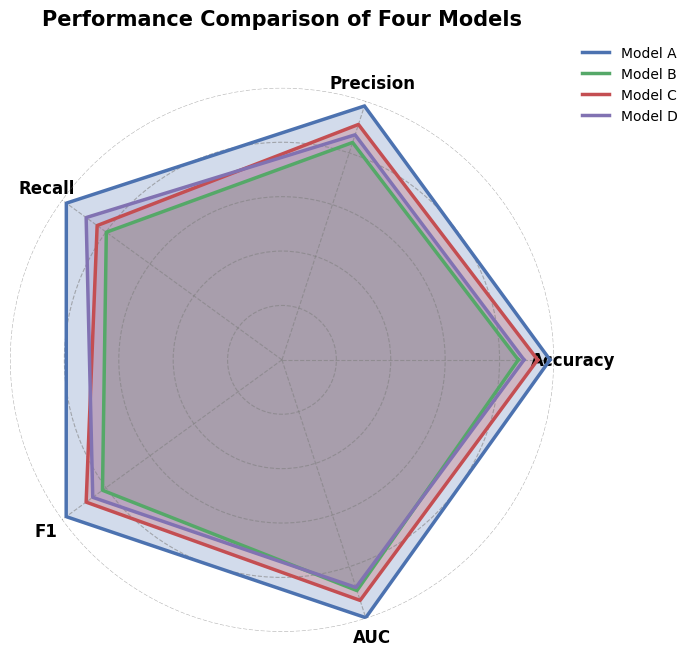

In [10]:
import numpy as np
import matplotlib.pyplot as plt

def plot_radar_chart(data_dict, labels, title="Model Performance Comparison",
                     colors=None, figsize=(7,7), alpha=0.25):
    num_vars = len(labels)
    angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
    angles += angles[:1]  # 闭合多边形

    fig, ax = plt.subplots(figsize=figsize, subplot_kw=dict(polar=True))
    plt.xticks(angles[:-1], labels, fontsize=12, fontweight='bold')
    ax.set_yticklabels([])
    ax.set_ylim(0, 1)

    # 默认颜色
    if colors is None:
        colors = ['#4C72B0', '#55A868', '#C44E52', '#8172B2', '#CCB974']

    # 绘制每个模型
    for i, (model, values) in enumerate(data_dict.items()):
        values = list(values) + [values[0]]  # 闭合
        ax.plot(angles, values, color=colors[i % len(colors)], linewidth=2.5, label=model)
        ax.fill(angles, values, color=colors[i % len(colors)], alpha=alpha)

    # 美化样式
    ax.spines['polar'].set_visible(False)
    ax.grid(color='grey', linestyle='--', linewidth=0.8, alpha=0.6)
    ax.set_title(title, size=15, y=1.1, fontweight='bold')
    ax.legend(loc='upper right', bbox_to_anchor=(1.25, 1.1), frameon=False)
    plt.tight_layout()
    plt.show()


# ======================
# ✅ 示例数据
# ======================
labels = ['Accuracy', 'Precision', 'Recall', 'F1', 'AUC']
data = {
    'Model A': [0.98545, 0.98141, 0.98003, 0.98072, 0.99683],
    'Model B': [0.86905, 0.84031, 0.79833, 0.81578, 0.89199],
    'Model C': [0.94, 0.91, 0.84, 0.89, 0.93],
    'Model D': [0.89, 0.87, 0.89, 0.86, 0.88],
}

# ✅ 调用函数
plot_radar_chart(data, labels, title="Performance Comparison of Four Models")

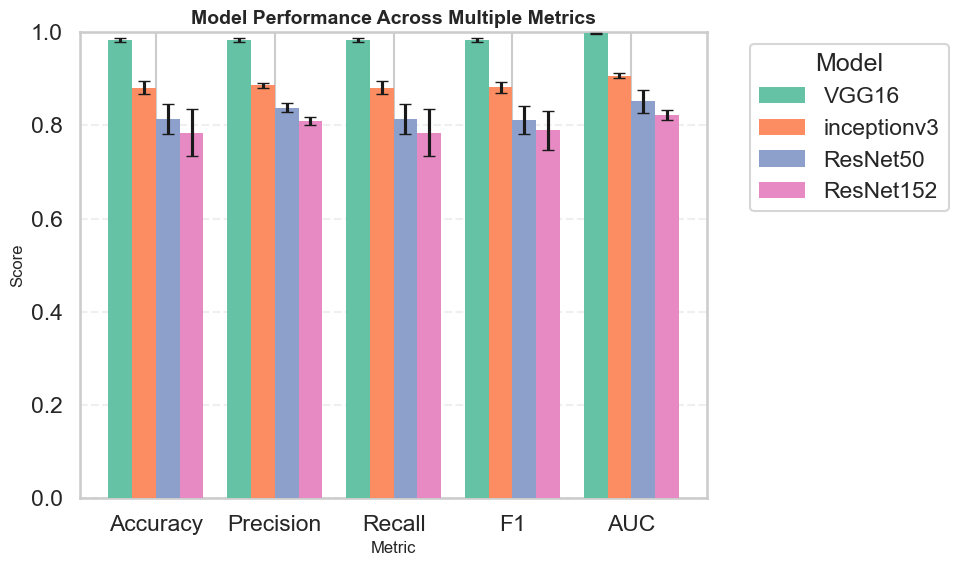

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 示例数据
data = {
    "Metric": ["Accuracy", "Precision", "Recall", "F1", "AUC"],
    "VGG16_mean": [0.9833, 0.9836, 0.9833, 0.9833, 0.9975],
    "VGG16_std":  [0.0043, 0.0038, 0.0043, 0.0042, 0.0004],
    "ResNet50_mean": [0.8138, 0.8381, 0.8138, 0.8116, 0.8518],
    "ResNet50_std":  [0.0322, 0.0093, 0.0322, 0.0299, 0.0248],
    "ResNet152_mean": [0.7848, 0.8097, 0.7848, 0.7894, 0.8234],
    "ResNet152_std":  [0.0511, 0.0089, 0.0511, 0.0425, 0.0109],
    "inceptionv3_mean": [0.8808, 0.8859, 0.8808, 0.8817, 0.9068],
    "inceptionv3_std":  [0.0138, 0.0059, 0.0138, 0.0116, 0.0054]
}
df = pd.DataFrame(data)

# 固定顺序
metric_order = ["Accuracy", "Precision", "Recall", "F1", "AUC"]
model_order  = ["VGG16", "inceptionv3", "ResNet50", "ResNet152"]

# 取指定顺序的数据表
df = df.set_index("Metric").loc[metric_order]

# 分组条形图手工定位
x = np.arange(len(metric_order))            # 每个指标的x位置
group_width = 0.8                           # 一组柱子的总宽度
bar_width   = group_width / len(model_order)

palette = sns.color_palette("Set2", n_colors=len(model_order))
fig, ax = plt.subplots(figsize=(10, 6))

for j, model in enumerate(model_order):
    means = df[f"{model}_mean"].values
    stds  = df[f"{model}_std"].values
    # 每个模型在一组里的位置：左移半组宽，再按列序加偏移
    pos = x - group_width/2 + bar_width/2 + j*bar_width

    # 误差线裁剪到 [0, 1]，避免越界
    upper = np.minimum(1.0, means + stds) - means
    lower = means - np.maximum(0.0, means - stds)
    yerr  = np.vstack([lower, upper])  # 非对称误差

    ax.bar(pos, means,
           width=bar_width,
           label=model,
           color=palette[j],
           edgecolor="none",
           linewidth=0.6,
           yerr=yerr,
           capsize=4,
           zorder=3)

# 坐标与样式
ax.set_xticks(x)
ax.set_xticklabels(metric_order)
ax.set_ylim(0, 1)  # 纵坐标 0~1
ax.set_ylabel("Score", fontsize=12)
ax.set_xlabel("Metric", fontsize=12)
ax.set_title("Model Performance Across Multiple Metrics", fontsize=14, weight="bold")
ax.legend(title="Model", bbox_to_anchor=(1.05, 1), loc="upper left")
ax.grid(axis="y", linestyle="--", alpha=0.3, zorder=0)
plt.tight_layout()
plt.show()